In [1]:
# Install required packages (safe to run multiple times)
%pip install -q numpy pandas matplotlib scikit-learn


Note: you may need to restart the kernel to use updated packages.


# MACHINE LEARNING — LAB 7: Naive Bayes
## Spam Detection & Sentiment Analysis

**Week 7 — Fall 2026 — BS Computer Science, 5th Semester**

### Student Information
- **Name:** vishaka kumari
- **cms ID:** 023-24-0224
- **Section:** G
- **GitHub Profile:** https://github.com/vishakakumaribscsf24-design/ML_Labs
- **Kaggle Profile:** https://www.kaggle.com/vishakakumari9

**Datasets**
1. SMS Spam Collection
2. Twitter US Airline Sentiment

> This notebook follows the supplied Week 7 lab manual: clean → vectorize → train Multinomial Naive Bayes → evaluate → interpret → compare with Logistic Regression.


In [2]:
# Imports
import os
import re
import glob
import zipfile
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, ConfusionMatrixDisplay
)

RANDOM_STATE = 42

print("Python/ML environment ready.")


Python/ML environment ready.


In [3]:
# ============================================================
# DATA SETUP — RAW FILES IN, CLEANED FILES OUT
# ============================================================

from pathlib import Path

# Works in Google Colab (/content) and in a normal local Jupyter/VS Code folder.
BASE_DIR = Path("/content") if Path("/content").exists() else Path(".")

SPAM_FILE = BASE_DIR / "spam.csv"
TWEETS_FILE = BASE_DIR / "Tweets.csv"

CLEANED_SPAM_FILE = BASE_DIR / "cleaned_spam.csv"
CLEANED_SENTIMENT_FILE = BASE_DIR / "cleaned_sentiment.csv"

print("Looking for:")
print("  Raw SMS file:   ", SPAM_FILE)
print("  Raw Tweets file:", TWEETS_FILE)

if not SPAM_FILE.exists():
    raise FileNotFoundError(
        f"Could not find {SPAM_FILE.name}. Put spam.csv in the same folder as this notebook."
    )

if not TWEETS_FILE.exists():
    raise FileNotFoundError(
        f"Could not find {TWEETS_FILE.name}. Put Tweets.csv in the same folder as this notebook."
    )

print("\n✓ Both raw CSV files found.")


Looking for:
  Raw SMS file:    spam.csv
  Raw Tweets file: Tweets.csv

✓ Both raw CSV files found.


In [4]:
# ============================================================
# TEXT CLEANING FUNCTIONS
# ============================================================

def clean_text(text):
    text = str(text).lower()
    text = re.sub(r"[^a-z0-9\s]", " ", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text

def clean_tweet(text):
    text = str(text).lower()
    text = re.sub(r"http\S+|www\.\S+", " ", text)
    text = re.sub(r"@\w+", " ", text)
    text = re.sub(r"[^a-z0-9\s]", " ", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text


In [5]:
# ============================================================
# LOAD RAW DATA + CREATE CLEANED CSV FILES
# ============================================================

# ---------- Task A: SMS Spam ----------
spam_df = pd.read_csv(SPAM_FILE, encoding="latin-1")

# The Kaggle SMS file normally has v1/v2 plus unused columns.
spam_df = spam_df.rename(columns={
    spam_df.columns[0]: "label",
    spam_df.columns[1]: "message"
})
spam_df = spam_df[["label", "message"]].dropna().copy()

# Keep only the two expected classes.
spam_df["label"] = spam_df["label"].str.lower().str.strip()
spam_df = spam_df[spam_df["label"].isin(["ham", "spam"])].copy()

# Light cleaning required by the lab.
spam_df["clean_message"] = spam_df["message"].apply(clean_text)
spam_df["target"] = spam_df["label"].map({"ham": 0, "spam": 1})

# Save a separate cleaned file — RAW spam.csv is untouched.
spam_df.to_csv(CLEANED_SPAM_FILE, index=False)

# ---------- Task B: Twitter Sentiment ----------
tweets_df = pd.read_csv(TWEETS_FILE)

# Keep positive/negative only, exactly as required by the lab.
sentiment_df = tweets_df[
    tweets_df["airline_sentiment"].isin(["positive", "negative"])
].copy()

# Clean tweets: lowercase, remove links and @mentions, remove punctuation.
sentiment_df["clean_text"] = sentiment_df["text"].apply(clean_tweet)
sentiment_df["target"] = sentiment_df["airline_sentiment"].map({
    "negative": 0,
    "positive": 1
})

# Save a separate cleaned file — RAW Tweets.csv is untouched.
sentiment_df.to_csv(CLEANED_SENTIMENT_FILE, index=False)

print("✓ Raw datasets loaded.")
print("✓ Cleaning completed.")
print("\nNew cleaned files created:")
print("  ", CLEANED_SPAM_FILE)
print("  ", CLEANED_SENTIMENT_FILE)

print("\nCleaned SMS shape:", spam_df.shape)
print("Cleaned sentiment shape:", sentiment_df.shape)

print("\nRAW files were not overwritten.")


✓ Raw datasets loaded.
✓ Cleaning completed.

New cleaned files created:
   cleaned_spam.csv
   cleaned_sentiment.csv

Cleaned SMS shape: (5572, 4)
Cleaned sentiment shape: (11541, 17)

RAW files were not overwritten.


In [6]:
# Task 3 — Task A Train/Test Split
X_spam = spam_df['clean_message']
y_spam = spam_df['target']

X_spam_train, X_spam_test, y_spam_train, y_spam_test = train_test_split(
    X_spam,
    y_spam,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y_spam
)

print('Training messages:', len(X_spam_train))
print('Test messages:', len(X_spam_test))
print('Training spam rate:', round(y_spam_train.mean(), 4))
print('Test spam rate:', round(y_spam_test.mean(), 4))


Training messages: 4457
Test messages: 1115
Training spam rate: 0.1342
Test spam rate: 0.1336


In [7]:
# Task 4 — Task A Vectorization (fit on training data only)
from sklearn.feature_extraction.text import CountVectorizer

vectorizer_spam = CountVectorizer()
X_spam_train_vec = vectorizer_spam.fit_transform(X_spam_train)
X_spam_test_vec = vectorizer_spam.transform(X_spam_test)

print('Training matrix:', X_spam_train_vec.shape)
print('Testing matrix :', X_spam_test_vec.shape)


Training matrix: (4457, 7658)
Testing matrix : (1115, 7658)


,Metric,Score
0,Accuracy,0.9839
1,Precision,0.9645
2,Recall,0.9128
3,F1-score,0.9379


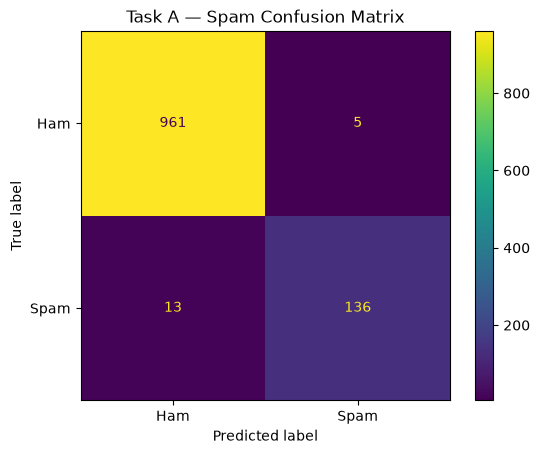

Interpretation: The model achieved 0.984 accuracy, 0.965 precision, 0.913 recall, and 0.938 F1-score on the held-out test set.


In [8]:
# Task 5 — Multinomial Naive Bayes
nb_spam = MultinomialNB()
nb_spam.fit(X_spam_train_vec, y_spam_train)

spam_pred = nb_spam.predict(X_spam_test_vec)

spam_accuracy = accuracy_score(y_spam_test, spam_pred)
spam_precision = precision_score(y_spam_test, spam_pred, zero_division=0)
spam_recall = recall_score(y_spam_test, spam_pred, zero_division=0)
spam_f1 = f1_score(y_spam_test, spam_pred, zero_division=0)

spam_metrics = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1-score"],
    "Score": [spam_accuracy, spam_precision, spam_recall, spam_f1]
})

display(spam_metrics.round(4))

cm_spam = confusion_matrix(y_spam_test, spam_pred)
disp = ConfusionMatrixDisplay(cm_spam, display_labels=["Ham", "Spam"])
disp.plot()
plt.title("Task A — Spam Confusion Matrix")
plt.show()

print(
    f"Interpretation: The model achieved {spam_accuracy:.3f} accuracy, "
    f"{spam_precision:.3f} precision, {spam_recall:.3f} recall, and "
    f"{spam_f1:.3f} F1-score on the held-out test set."
)


In [9]:
# Task 7 — top 15 spam-associated and ham-associated words
feature_names = vectorizer_spam.get_feature_names_out()
log_probs = nb_spam.feature_log_prob_

# Class 0 = ham, Class 1 = spam
log_diff = log_probs[1] - log_probs[0]

spam_top_idx = np.argsort(log_diff)[-15:][::-1]
ham_top_idx = np.argsort(log_diff)[:15]

top_spam_words = pd.DataFrame({
    "Word": feature_names[spam_top_idx],
    "Spam_minus_Ham_LogProb": log_diff[spam_top_idx]
})

top_ham_words = pd.DataFrame({
    "Word": feature_names[ham_top_idx],
    "Spam_minus_Ham_LogProb": log_diff[ham_top_idx]
})

print("15 words most strongly associated with SPAM:")
display(top_spam_words)

print("15 words most strongly associated with HAM:")
display(top_ham_words)

print(
    "\nInterpretation: Inspect whether the highest-ranked words make intuitive "
    "sense as promotional/urgent spam language versus ordinary conversational language."
)


15 words most strongly associated with SPAM:


,Word,Spam_minus_Ham_LogProb
0,claim,5.530667
1,prize,5.196298
2,150p,4.984124
3,tone,4.826938
4,18,4.714460
5,cs,4.665670
6,500,4.614376
7,guaranteed,4.614376
8,1000,4.503151
9,uk,4.442526


15 words most strongly associated with HAM:


,Word,Spam_minus_Ham_LogProb
0,gt,-4.587730
1,lt,-4.572286
2,he,-4.104614
3,da,-3.890744
4,lor,-3.890744
5,she,-3.859492
6,later,-3.785384
7,ll,-3.336243
8,doing,-3.299876
9,say,-3.271705



Interpretation: Inspect whether the highest-ranked words make intuitive sense as promotional/urgent spam language versus ordinary conversational language.


In [10]:
# Task 8 — custom test messages
test_messages = [
    "Congratulations! You won a free cash prize. Click now to claim your reward!",
    "URGENT! You have been selected for a £5000 reward. Call now.",
    "Hi, I will reach home around 7 pm. Please keep dinner ready.",
    "Can you send me the notes from today's class?"
]

test_clean = [clean_text(x) for x in test_messages]
test_vec = vectorizer_spam.transform(test_clean)
test_pred = nb_spam.predict(test_vec)
test_prob = nb_spam.predict_proba(test_vec)[:, 1]

test_results = pd.DataFrame({
    "Message": test_messages,
    "Prediction": np.where(test_pred == 1, "spam", "ham"),
    "Spam_Probability": test_prob.round(4)
})

display(test_results)

print(
    "Interpretation: The first two messages are intentionally spam-like, while "
    "the last two are ordinary messages. Compare the model predictions with these expectations."
)


,Message,Prediction,Spam_Probability
0,Congratulations! You won a free cash prize. Cl...,spam,1.0000
1,URGENT! You have been selected for a £5000 rew...,spam,1.0000
2,"Hi, I will reach home around 7 pm. Please keep...",ham,0.0000
3,Can you send me the notes from today's class?,ham,0.0001


Interpretation: The first two messages are intentionally spam-like, while the last two are ordinary messages. Compare the model predictions with these expectations.


In [11]:
# Task 11 & 12 — prepare Task B features

X_sent = sentiment_df["clean_text"]
y_sent = sentiment_df["target"]

X_sent_train, X_sent_test, y_sent_train, y_sent_test = train_test_split(
    X_sent, y_sent,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y_sent
)

# TF-IDF is used for Task B; vocabulary is fitted on training tweets only.
vectorizer_sent = TfidfVectorizer()
X_sent_train_vec = vectorizer_sent.fit_transform(X_sent_train)
X_sent_test_vec = vectorizer_sent.transform(X_sent_test)

print("Training documents:", X_sent_train_vec.shape[0])
print("Test documents:", X_sent_test_vec.shape[0])
print("Vocabulary size:", X_sent_train_vec.shape[1])

print(
    "\nCleaning justification: Tweets contain URLs and @mentions that can create "
    "many highly specific tokens. Removing them reduces noisy vocabulary while keeping "
    "sentiment-bearing words in the tweet text."
)


Training documents: 9232
Test documents: 2309
Vocabulary size: 10077

Cleaning justification: Tweets contain URLs and @mentions that can create many highly specific tokens. Removing them reduces noisy vocabulary while keeping sentiment-bearing words in the tweet text.


,Metric,Score
0,Accuracy,0.8311
1,Precision,1.0000
2,Recall,0.1755
3,F1-score,0.2986


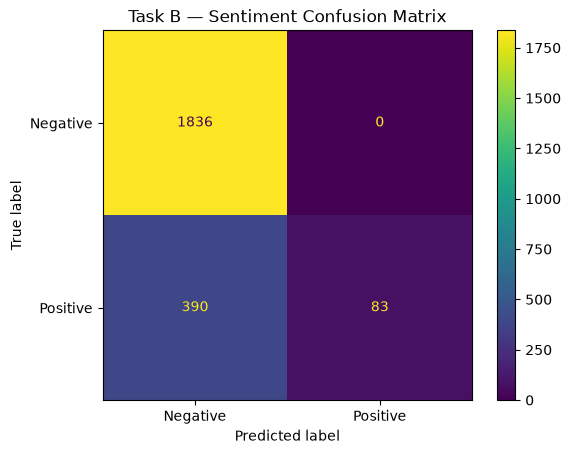

Interpretation: The sentiment model achieved 0.831 accuracy, 1.000 precision, 0.175 recall, and 0.299 F1-score.


In [12]:
# Task 13 — Multinomial Naive Bayes on sentiment
nb_sent = MultinomialNB()
nb_sent.fit(X_sent_train_vec, y_sent_train)

sent_pred = nb_sent.predict(X_sent_test_vec)

sent_accuracy = accuracy_score(y_sent_test, sent_pred)
sent_precision = precision_score(y_sent_test, sent_pred, zero_division=0)
sent_recall = recall_score(y_sent_test, sent_pred, zero_division=0)
sent_f1 = f1_score(y_sent_test, sent_pred, zero_division=0)

sent_metrics = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1-score"],
    "Score": [sent_accuracy, sent_precision, sent_recall, sent_f1]
})

display(sent_metrics.round(4))

cm_sent = confusion_matrix(y_sent_test, sent_pred)
disp = ConfusionMatrixDisplay(cm_sent, display_labels=["Negative", "Positive"])
disp.plot()
plt.title("Task B — Sentiment Confusion Matrix")
plt.show()

print(
    f"Interpretation: The sentiment model achieved {sent_accuracy:.3f} accuracy, "
    f"{sent_precision:.3f} precision, {sent_recall:.3f} recall, and "
    f"{sent_f1:.3f} F1-score."
)


In [13]:
# Task 17 — Naive Bayes: Task A vs Task B
comparison_nb = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1-score"],
    "Task A — Spam": [spam_accuracy, spam_precision, spam_recall, spam_f1],
    "Task B — Sentiment": [sent_accuracy, sent_precision, sent_recall, sent_f1]
})

display(comparison_nb.round(4))


,Metric,Task A — Spam,Task B — Sentiment
0,Accuracy,0.9839,0.8311
1,Precision,0.9645,1.0000
2,Recall,0.9128,0.1755
3,F1-score,0.9379,0.2986


In [14]:
# Task 18 — Logistic Regression vs Naive Bayes on Task A
lr_spam = LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)
lr_spam.fit(X_spam_train_vec, y_spam_train)

lr_pred = lr_spam.predict(X_spam_test_vec)

lr_accuracy = accuracy_score(y_spam_test, lr_pred)
lr_precision = precision_score(y_spam_test, lr_pred, zero_division=0)
lr_recall = recall_score(y_spam_test, lr_pred, zero_division=0)
lr_f1 = f1_score(y_spam_test, lr_pred, zero_division=0)

comparison_lr = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1-score"],
    "Naive Bayes": [spam_accuracy, spam_precision, spam_recall, spam_f1],
    "Logistic Regression": [lr_accuracy, lr_precision, lr_recall, lr_f1]
})

display(comparison_lr.round(4))

print(
    "\nInterpretation: Compare the four metrics directly. "
    "The difference is empirical for this dataset/split; it should not be explained "
    "only from the algorithms' assumptions."
)


,Metric,Naive Bayes,Logistic Regression
0,Accuracy,0.9839,0.9812
1,Precision,0.9645,0.9923
2,Recall,0.9128,0.8658
3,F1-score,0.9379,0.9247



Interpretation: Compare the four metrics directly. The difference is empirical for this dataset/split; it should not be explained only from the algorithms' assumptions.
